# 04 — Model training

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

BRANCHES = ["original", "seasonal", "trend"]
SUFFIX = {"original": "", "seasonal": "_S", "trend": "_T"}
data = {b: pd.read_csv(f"../data/processed/features_{b}.csv",
                       index_col="date", parse_dates=True) for b in BRANCHES}


def split(df):
    X = df.drop(columns=["target", "split"])
    train = df["split"] == "train"
    return X[train], X[~train], df.loc[train, "target"], df.loc[~train, "target"]


for b, df in data.items():
    Xtr, Xte, ytr, yte = split(df)
    print(f"{b:9s} {Xtr.shape[1]:2d} features | "
          f"train {len(Xtr)} ({Xtr.index.min():%Y-%m}..{Xtr.index.max():%Y-%m}) | "
          f"test {len(Xte)} ({Xte.index.min():%Y-%m}..{Xte.index.max():%Y-%m})")

original   6 features | train 238 (2002-03..2021-12) | test 36 (2022-01..2024-12)
seasonal   7 features | train 238 (2002-03..2021-12) | test 36 (2022-01..2024-12)
trend      5 features | train 252 (2001-01..2021-12) | test 36 (2022-01..2024-12)


## Hyperparameter tuning

In [2]:
SEED = 0
CV = TimeSeriesSplit(n_splits=5)

MODELS = {
    "XGBoost": (XGBRegressor(random_state=SEED, n_jobs=1), {
        "n_estimators": randint(200, 800), "max_depth": randint(2, 7),
        "learning_rate": loguniform(0.01, 0.2), "subsample": uniform(0.6, 0.4),
        "colsample_bytree": uniform(0.6, 0.4), "min_child_weight": randint(1, 11)}),
    "RandomForest": (RandomForestRegressor(random_state=SEED, n_jobs=1), {
        "n_estimators": randint(300, 800), "max_depth": [None, 4, 6, 8, 12],
        "min_samples_leaf": randint(1, 11), "max_features": ["sqrt", 0.5, 1.0]}),
    "Ridge": (make_pipeline(StandardScaler(), Ridge()), {
        "ridge__alpha": np.logspace(-4, 3, 50)}),
}


def tune(name, X, y):
    est, space = MODELS[name]
    if name == "Ridge":
        search = GridSearchCV(est, space, cv=CV,
                              scoring="neg_mean_squared_error", n_jobs=-1)
    else:
        search = RandomizedSearchCV(est, space, n_iter=40, cv=CV,
                                    scoring="neg_mean_squared_error",
                                    random_state=SEED, n_jobs=-1)
    return search.fit(X, y)


best_params = {}
for b, df in data.items():
    Xtr, _, ytr, _ = split(df)
    for name in MODELS:
        search = tune(name, Xtr, ytr)
        best_params[(b, name)] = search.best_params_
        print(f"{b:9s} {name:12s} CV RMSE {np.sqrt(-search.best_score_):.4f}")

original  XGBoost      CV RMSE 0.0293


original  RandomForest CV RMSE 0.0284
original  Ridge        CV RMSE 0.0307


seasonal  XGBoost      CV RMSE 0.0261


seasonal  RandomForest CV RMSE 0.0255


seasonal  Ridge        CV RMSE 0.0285


trend     XGBoost      CV RMSE 0.0099


trend     RandomForest CV RMSE 0.0099


trend     Ridge        CV RMSE 0.0018


## Test period

In [3]:
def make_model(b, name, seed=SEED):
    est = clone(MODELS[name][0]).set_params(**best_params[(b, name)])
    if name != "Ridge":
        est.set_params(random_state=seed)
    return est


def scores(y, p):
    return dict(RMSE=np.sqrt(mean_squared_error(y, p)), R2=r2_score(y, p),
                MAE=mean_absolute_error(y, p))


def baselines(b, df, test_mask):
    y = df["target"]
    persistence = df[f"NDVI{SUFFIX[b]}_lag1"]
    clim = y[~test_mask].groupby(y[~test_mask].index.month).mean()
    climatology = pd.Series(y.index.month.map(clim), index=y.index)
    return {"persistence": persistence, "climatology": climatology}


rows, predictions = [], {}
for b, df in data.items():
    Xtr, Xte, ytr, yte = split(df)
    test = df["split"] == "test"
    for name in MODELS:
        p = make_model(b, name).fit(Xtr, ytr).predict(Xte)
        predictions[(b, name)] = pd.Series(p, index=Xte.index)
        rows.append(dict(branch=b, model=name, **scores(yte, p)))
    for name, s in baselines(b, df, test).items():
        predictions[(b, name)] = s[test]
        rows.append(dict(branch=b, model=name, **scores(yte, s[test])))

test_scores = pd.DataFrame(rows)
ORDER = ["XGBoost", "RandomForest", "Ridge", "persistence", "climatology"]
for metric in ["RMSE", "R2", "MAE"]:
    print(f"\n{metric}")
    print(test_scores.pivot(index="model", columns="branch", values=metric)
                     .loc[ORDER, BRANCHES].round(4).to_string())


RMSE
branch        original  seasonal   trend
model                                   
XGBoost         0.0366    0.0363  0.0023
RandomForest    0.0397    0.0326  0.0018
Ridge           0.0369    0.0348  0.0015
persistence     0.0571    0.0569  0.0017
climatology     0.0328    0.0333  0.0122

R2
branch        original  seasonal   trend
model                                   
XGBoost         0.3466    0.3215  0.9578
RandomForest    0.2313    0.4536  0.9739
Ridge           0.3379    0.3757  0.9832
persistence    -0.5892   -0.6680  0.9773
climatology     0.4760    0.4294 -0.1860

MAE
branch        original  seasonal   trend
model                                   
XGBoost         0.0266    0.0285  0.0018
RandomForest    0.0282    0.0253  0.0015
Ridge           0.0264    0.0268  0.0012
persistence     0.0408    0.0408  0.0013
climatology     0.0265    0.0261  0.0109


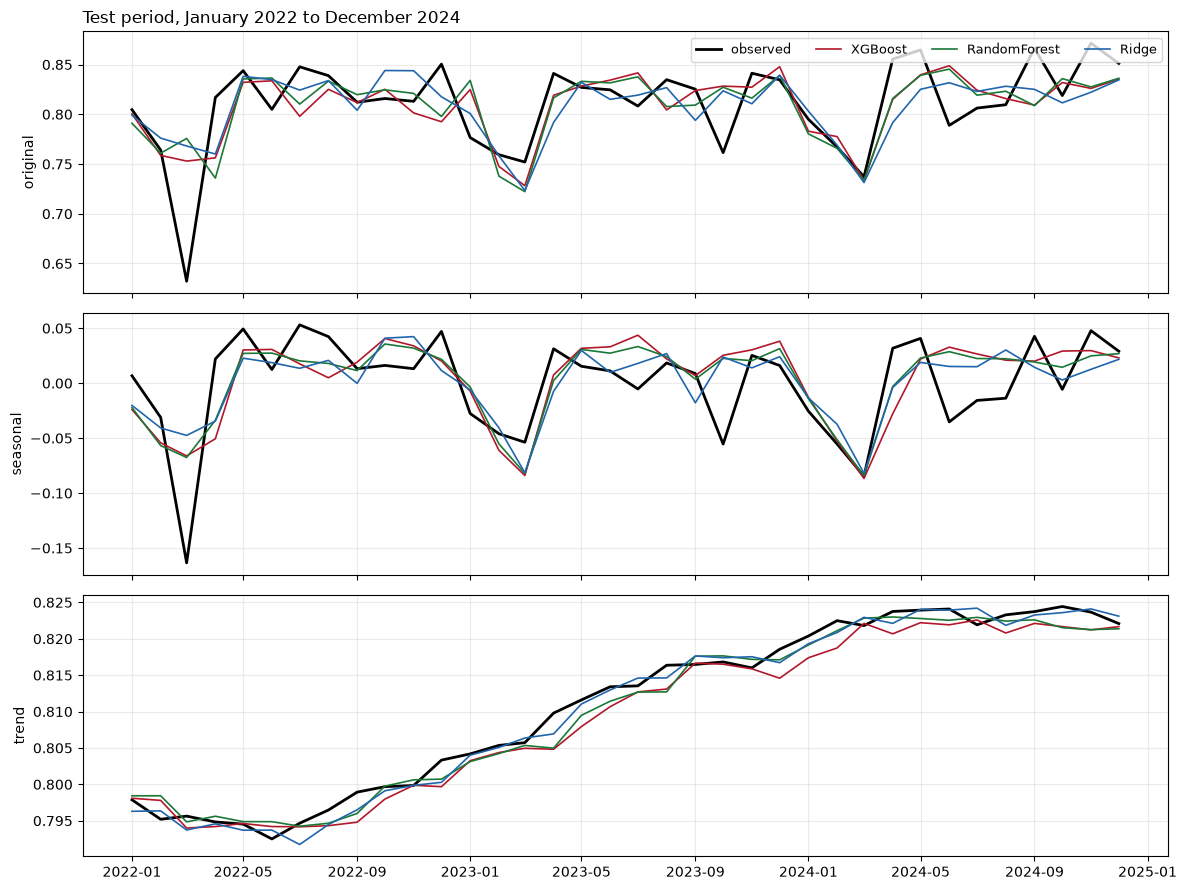

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
colors = {"XGBoost": "#b2182b", "RandomForest": "#1b7837", "Ridge": "#2166ac"}
for ax, b in zip(axes, BRANCHES):
    _, Xte, _, yte = split(data[b])
    ax.plot(yte.index, yte, color="black", lw=2, label="observed")
    for name, c in colors.items():
        ax.plot(yte.index, predictions[(b, name)], color=c, lw=1.2, label=name)
    ax.set_ylabel(b)
    ax.grid(alpha=0.25)
axes[0].legend(ncol=4, loc="upper right", fontsize=9)
axes[0].set_title("Test period, January 2022 to December 2024", loc="left")
fig.tight_layout()
fig.savefig("../figures/04_test_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

## Noise floor

In [5]:
floor = []
for b, df in data.items():
    Xtr, Xte, ytr, yte = split(df)
    for name in MODELS:
        seeds = [SEED] if name == "Ridge" else range(20)
        runs = [scores(yte, make_model(b, name, s).fit(Xtr, ytr).predict(Xte)) for s in seeds]
        floor.append(dict(branch=b, model=name,
                          RMSE_mean=np.mean([r["RMSE"] for r in runs]),
                          RMSE_sd=np.std([r["RMSE"] for r in runs]),
                          R2_mean=np.mean([r["R2"] for r in runs]),
                          R2_sd=np.std([r["R2"] for r in runs])))

noise_floor = pd.DataFrame(floor)
print(noise_floor.round(4).to_string(index=False))

  branch        model  RMSE_mean  RMSE_sd  R2_mean  R2_sd
original      XGBoost     0.0364   0.0002   0.3549 0.0062
original RandomForest     0.0401   0.0003   0.2174 0.0137
original        Ridge     0.0369   0.0000   0.3379 0.0000
seasonal      XGBoost     0.0359   0.0003   0.3364 0.0119
seasonal RandomForest     0.0327   0.0002   0.4508 0.0059
seasonal        Ridge     0.0348   0.0000   0.3757 0.0000
   trend      XGBoost     0.0033   0.0005   0.9121 0.0237
   trend RandomForest     0.0018   0.0000   0.9736 0.0006
   trend        Ridge     0.0015   0.0000   0.9832 0.0000


## Rolling-origin evaluation

In [6]:
WINDOWS = [("2010-01-01", "2012-12-01"), ("2013-01-01", "2015-12-01"),
           ("2016-01-01", "2018-12-01"), ("2019-01-01", "2021-12-01"),
           ("2022-01-01", "2024-12-01")]

folds = []
for b, df in data.items():
    X, y = df.drop(columns=["target", "split"]), df["target"]
    for start, end in WINDOWS:
        tr, te = df.index < start, (df.index >= start) & (df.index <= end)
        for name in MODELS:
            p = make_model(b, name).fit(X[tr], y[tr]).predict(X[te])
            folds.append(dict(branch=b, window=start[:4] + "-" + end[2:4], model=name,
                              RMSE=np.sqrt(mean_squared_error(y[te], p)),
                              R2=r2_score(y[te], p)))
        for name, s in baselines(b, df, ~tr).items():
            folds.append(dict(branch=b, window=start[:4] + "-" + end[2:4], model=name,
                              RMSE=np.sqrt(mean_squared_error(y[te], s[te])),
                              R2=r2_score(y[te], s[te])))

rolling = pd.DataFrame(folds)
order = ["XGBoost", "RandomForest", "Ridge", "persistence", "climatology"]
for b in BRANCHES:
    for metric, digits in [("RMSE", 4), ("R2", 3)]:
        t = rolling[rolling.branch == b].pivot(index="model", columns="window",
                                               values=metric).loc[order]
        t["mean"], t["sd"] = t.mean(axis=1), t.std(axis=1)
        print(f"\n{b} — {metric}"); print(t.round(digits).to_string())


original — RMSE
window        2010-12  2013-15  2016-18  2019-21  2022-24    mean      sd
model                                                                    
XGBoost        0.0332   0.0209   0.0210   0.0372   0.0366  0.0298  0.0082
RandomForest   0.0299   0.0223   0.0210   0.0384   0.0397  0.0303  0.0087
Ridge          0.0317   0.0214   0.0231   0.0404   0.0369  0.0307  0.0083
persistence    0.0473   0.0344   0.0334   0.0512   0.0571  0.0447  0.0105
climatology    0.0341   0.0256   0.0221   0.0415   0.0328  0.0312  0.0076

original — R2
window        2010-12  2013-15  2016-18  2019-21  2022-24   mean     sd
model                                                                  
XGBoost         0.577    0.639    0.695    0.451    0.347  0.542  0.142
RandomForest    0.657    0.589    0.695    0.414    0.231  0.518  0.193
Ridge           0.615    0.621    0.631    0.352    0.338  0.512  0.152
persistence     0.144    0.018    0.234   -0.039   -0.589 -0.047  0.321
climatology     0.

## Reconstruction

In [7]:
y_orig = split(data["original"])[3]
recon = []
for name in MODELS:
    p = (predictions[("seasonal", name)] + predictions[("trend", name)]).reindex(y_orig.index)
    direct = test_scores.query("branch == 'original' and model == @name").iloc[0]
    recon.append(dict(model=name,
                      RMSE_direct=direct.RMSE, RMSE_reconstructed=np.sqrt(mean_squared_error(y_orig, p)),
                      R2_direct=direct.R2, R2_reconstructed=r2_score(y_orig, p)))
print(pd.DataFrame(recon).round(4).to_string(index=False))

       model  RMSE_direct  RMSE_reconstructed  R2_direct  R2_reconstructed
     XGBoost       0.0366              0.0362     0.3466            0.3608
RandomForest       0.0397              0.0326     0.2313            0.4818
       Ridge       0.0369              0.0350     0.3379            0.4019


## Saving

In [8]:
json.dump({f"{b}|{m}": {k: (v.item() if hasattr(v, "item") else v) for k, v in p.items()}
           for (b, m), p in best_params.items()},
          open("../results/04_best_params.json", "w"), indent=2)
test_scores.to_csv("../results/04_test_scores.csv", index=False)
noise_floor.to_csv("../results/04_noise_floor.csv", index=False)
rolling.to_csv("../results/04_rolling_origin.csv", index=False)
pd.DataFrame({f"{b}|{m}": s for (b, m), s in predictions.items()}) \
  .to_csv("../results/04_test_predictions.csv")
print("saved")

saved
